# Task 1

Fetched code from the Frost website, lines in code box


In [15]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import requests

with open("client_id.txt", "r") as file:
    client_id = file.read().strip().split(":")[1].strip()


In [16]:
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()

In [17]:
# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])


Data retrieved from frost.met.no!


Inspired by the Frost code, but it was outdated

In [18]:
rows = []
for item in data:
    observation = item['observations'][0]
    rows.append({
        'date': pd.to_datetime(item['referenceTime']).tz_localize(None).normalize(),
        'source_Id': item['sourceId'],
        'element_Id': observation['elementId'],
        'temperature': observation['value'],
        'unit': observation['unit'],
        'time_offset': observation['timeOffset']
    })
df = pd.DataFrame(rows).set_index('date')

df.head()

,source_Id,element_Id,temperature,unit,time_offset
date,,,,,
2025-01-01,SN17850:0,mean(air_temperature P1D),-5.2,degC,PT0H
2025-01-02,SN17850:0,mean(air_temperature P1D),-11.5,degC,PT0H
2025-01-03,SN17850:0,mean(air_temperature P1D),-8.9,degC,PT0H
2025-01-04,SN17850:0,mean(air_temperature P1D),-15.5,degC,PT0H
2025-01-05,SN17850:0,mean(air_temperature P1D),-12.5,degC,PT0H


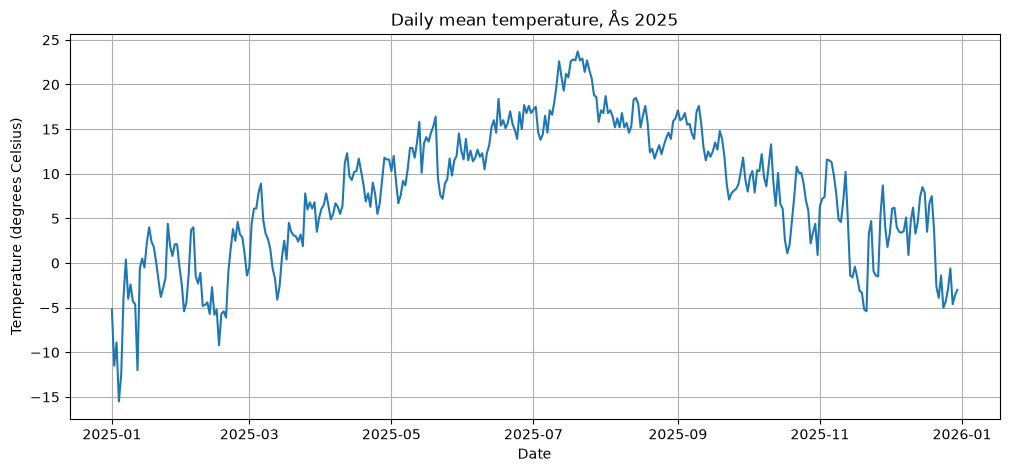

In [19]:
fig, ax = plt.subplots(figsize=(12, 5)) 
ax.plot(df.index,df['temperature'])
ax.set_title('Daily mean temperature, Ås 2025')
ax.set_xlabel('Date')
ax.set_ylabel('Temperature (degrees Celsius)')
ax.grid()
plt.show()


In [20]:
print('Air temperature summary, Ås 2025')
print('-' * len('Air temperature summary, Ås 2025'))
print(f"{'Average':<15}{df['temperature'].mean():>8.1f} °C")
print(f"{'Median':<15}{df['temperature'].median():>8.1f} °C")
print(f"{'Minimum':<15}{df['temperature'].min():>8.1f} °C")
print(f"{'Maximum':<15}{df['temperature'].max():>8.1f} °C")

Air temperature summary, Ås 2025
--------------------------------
Average             7.9 °C
Median              8.4 °C
Minimum           -15.5 °C
Maximum            23.7 °C


The plot presents the daily mean temperatures recorded at Ås in
2025. Daily values show short-term temperature variations, while
the summary statistics describe the overall temperature level
and range during the available observation period.

The mean and median provide two measures of the central
temperature level. The minimum and maximum refer to daily mean
temperatures, rather than the coldest and warmest individual
measurements within a day

# Task 2

Created a function for reuse in tasks 3 and 4 to avoid too much repetition

In [21]:
def get_frost_periods(source_id, element, start, end, client_id):
    r = requests.get('https://frost.met.no/observations/v0.jsonld',
                     {'sources': source_id,
                      'elements': element,
                      'referencetime': f'{start}/{end}'},
                      auth=(client_id,''))
    if r.status_code != 200:
        err = r.json()['error']
        raise RuntimeError(f"{r.status_code}: {err['message']} - {err['reason']}")
    return pd.Series(
        {pd.to_datetime(d['referenceTime']).tz_localize(None).normalize():
         d['observations'][0]['value'] for d in r.json()['data']}
    ).sort_index()

precipitation = get_frost_periods('SN17850', 'sum(precipitation_amount P1D)', '2025-01-01', '2025-12-31', client_id)

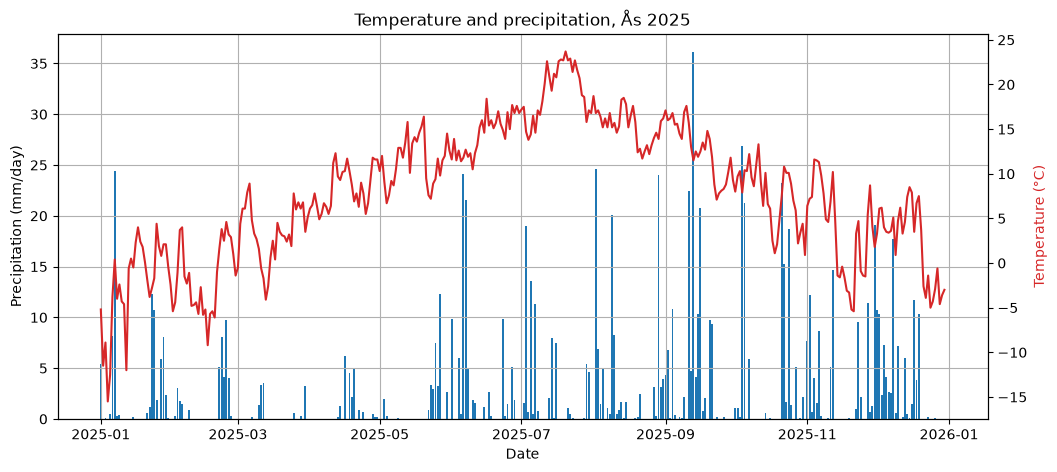

In [22]:
temperature = df['temperature']
fig, ax1 = plt.subplots(figsize=(12, 5)) 
ax1.bar(precipitation.index, precipitation.values)
ax1.set_xlabel('Date')
ax1.set_ylabel('Precipitation (mm/day)')

ax2 = ax1.twinx()
ax2.plot(temperature.index, temperature.values, color='tab:red', label='Mean temperature (°C)')
ax2.set_ylabel('Temperature (°C)', color='tab:red')

ax1.set_title('Temperature and precipitation, Ås 2025')
ax1.grid()
plt.show()

The plot displays daily precipitation and daily mean temperature
together, making it possible to compare their timing. Separate
vertical axes are necessary because precipitation is measured
in millimetres and temperature in degrees Celsius.

The height of a precipitation bar should therefore be read
against the precipitation axis, while the temperature curve
should be read against the temperature axis. The figure allows
visual comparisons, but it does not establish a statistical or
causal relationship between the two variables.


# Task 3

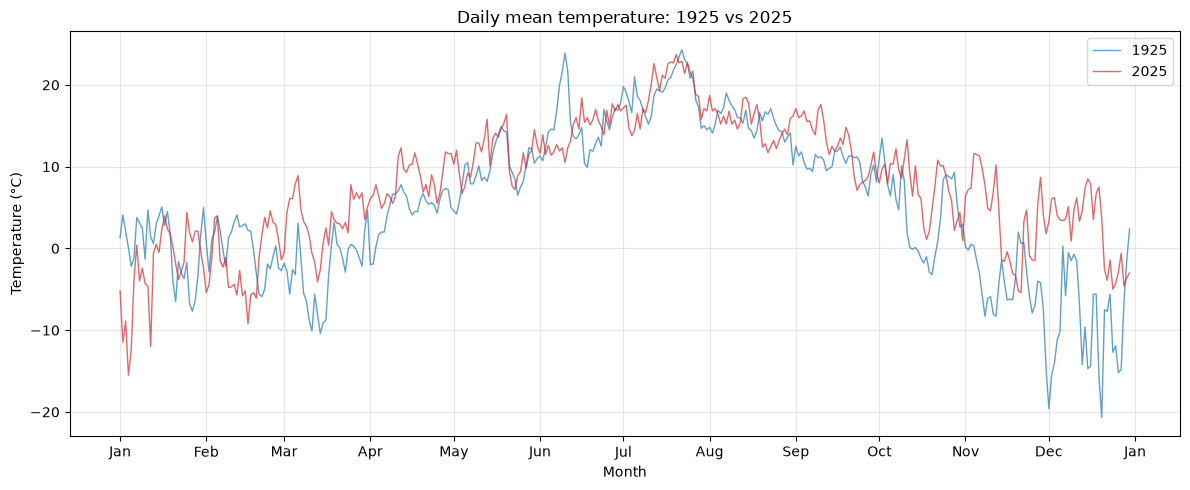

Daily mean temperature summary (°C)
         1925  2025
Average   5.3   7.9
Median    5.3   8.4
Minimum -20.7 -15.5
Maximum  24.3  23.7


In [23]:
old = get_frost_periods('SN17850', 'mean(air_temperature P1D)', '1925-01-01', '1925-12-31', client_id)
new = df['temperature']


def to_common_year(s):
    s = s.copy()
    s.index = pd.to_datetime({'year': 2001, 'month': s.index.month, 'day': s.index.day})
    return s

old_c = to_common_year(old)
new_c = to_common_year(new)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(old_c.index, old_c.values, color='tab:blue', alpha=0.7, linewidth=1, label='1925')
ax.plot(new_c.index, new_c.values, color='tab:red', alpha=0.7, linewidth=1, label='2025')
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.set_title('Daily mean temperature: 1925 vs 2025')
ax.set_xlabel('Month')
ax.set_ylabel('Temperature (°C)')
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

summary = pd.DataFrame({
    "1925": [
        old.mean(),
        old.median(),
        old.min(),
        old.max()
    ],
    "2025": [
        new.mean(),
        new.median(),
        new.min(),
        new.max()
    ]
}, index=["Average", "Median", "Minimum", "Maximum"])

print("Daily mean temperature summary (°C)")
print(summary.to_string(float_format=lambda value: f"{value:.1f}"))

The plot compares daily mean temperatures from 1925 and 2025
by aligning the same calendar dates. This makes it possible to
compare the years throughout the seasons. The common year used
for plotting changes only the displayed dates, not the
temperature values.

The summary table compares the mean, median, minimum and
maximum daily mean temperatures for each year. These statistics
describe different aspects of the temperature distributions,
while the plot shows when differences occur.

Two individual years at one station are insufficient to
establish a long-term climate trend. Missing observations
could also affect the comparison, particularly if they occur
in different seasons.

# Task 4

In [25]:
import yaml


def count_heatwaves(station_id, year, output_file=None):
    # Retrieve daily maximum temperature, not mean temperature.
    temperatures = get_frost_periods(
        station_id,
        "max(air_temperature P1D)",
        f"{year}-01-01",
        f"{year}-12-31",
        client_id
    )

    # Include all calendar days.
    # Missing temperatures become NaN and break a heatwave.
    days = pd.date_range(f"{year}-01-01", f"{year}-12-31")
    temperatures = temperatures.reindex(days)

    heatwaves = []
    start = None
    duration = 0

    for date, temperature in temperatures.items():
        if pd.notna(temperature) and temperature >= 27:
            if duration == 0:
                start = date

            duration += 1

        else:
            if duration >= 5:
                heatwaves.append({
                    "start": start.strftime("%Y-%m-%d"),
                    "end": (date - pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
                    "days": duration
                })

            start = None
            duration = 0

    # Also include a heatwave that ends on December 31, if any.
    if duration >= 5:
        heatwaves.append({
            "start": start.strftime("%Y-%m-%d"),
            "end": days[-1].strftime("%Y-%m-%d"),
            "days": duration
        })

    summary = {
        "station_id": station_id,
        "year": int(year),
        "number_of_heatwaves": len(heatwaves),
        "heatwaves": heatwaves
    }

    if output_file is None:
        output_file = f"heatwaves_{station_id}_{year}.yml"

    with open(output_file, "w", encoding="utf-8") as file:
        yaml.safe_dump(
            summary,
            file,
            allow_unicode=True,
            sort_keys=False
        )

    print(f"Number of heatwaves in {year}: {len(heatwaves)}")
    print(f"Results saved to {output_file}")

    return summary

summary = count_heatwaves("SN17850", 2025)


Number of heatwaves in 2025: 1
Results saved to heatwaves_SN17850_2025.yml


The function identifies heatwaves according to the assignment's
definition: at least five consecutive days with daily maximum
temperatures of 27 °C or higher. Daily maximum temperatures are
used because daily mean temperatures cannot determine whether
this threshold was reached.

Each uninterrupted qualifying period is counted as one
heatwave, even if it lasts longer than five days. The YAML
summary records the number of detected periods, their start
and end dates, and their duration.

A missing measurement interrupts a sequence in this
implementation. This prevents the function from assuming that
an unobserved day met the threshold, but it may cause a
heatwave to go undetected.

# Task 5

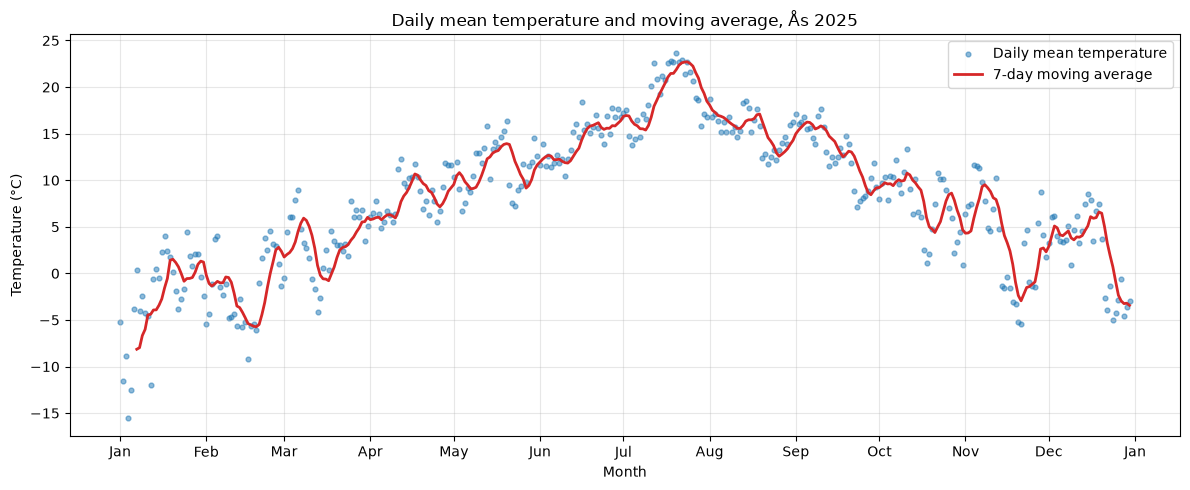

In [26]:
def moving_average(temperatures):
    temperatures = temperatures.copy().sort_index()

    # Insert missing calendar days.
    days = pd.date_range(
        temperatures.index.min(),
        temperatures.index.max()
    )
    temperatures = temperatures.reindex(days)

    return temperatures.rolling(window=7, min_periods=7).mean()


# Use the temperature data from task 1.
temperature = df["temperature"].copy().sort_index()
average = moving_average(temperature)

fig, ax = plt.subplots(figsize=(12, 5))

# Daily temperatures as points.
ax.scatter(
    temperature.index,
    temperature.values,
    color="tab:blue",
    s=12,
    alpha=0.5,
    label="Daily mean temperature"
)

# Moving average as a line.
ax.plot(
    average.index,
    average.values,
    color="tab:red",
    linewidth=2,
    label="7-day moving average"
)

ax.set_title("Daily mean temperature and moving average, Ås 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

The daily temperature points retain short-term variations,
while the seven-day moving average smooths these fluctuations.
The line therefore makes broader changes easier to follow,
but reduces the visibility of brief temperature extremes.

Each average uses the current day's temperature and the
previous six days. As a result, the curve responds more slowly
to sudden changes than the daily observations.

The calculation requires seven valid daily measurements.
Consequently, there are no moving-average values for the first
six days, and missing measurements create gaps in the curve.